# Resampling Methods: Bootstrap and Permutation Tests

Classical methods rely on formulas and distributional assumptions (normality, known standard errors). **Resampling methods** replace the formulas with computation: they reuse the observed data thousands of times to approximate a sampling distribution directly.

- The **bootstrap** estimates the uncertainty (standard error, confidence interval) of almost *any* statistic: median, correlation, ratio, model coefficient.
- **Permutation tests** compute a p-value by simulating what the data would look like if $H_0$ were true.

Both are intuitive, need few assumptions, and are widely used in modern data science.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. The Bootstrap Idea

We would like many samples from the population to see how a statistic varies, but we only have one sample. Bradley Efron (1979) proposed treating the sample **as if it were the population**:

1. Draw a **bootstrap sample**: $n$ observations from the data **with replacement**.
2. Compute the statistic $\hat{\theta}^*$ on it.
3. Repeat $B$ times (e.g. $B = 5{,}000$).
4. The spread of the $\hat{\theta}^*$ values approximates the sampling distribution:
$$
\widehat{SE}_{boot} = \text{sd}(\hat{\theta}^*_1, \dots, \hat{\theta}^*_B), \qquad
\text{95\% percentile CI} = \big[\hat{\theta}^*_{(2.5\%)},\; \hat{\theta}^*_{(97.5\%)}\big]
$$

In [2]:
set.seed(21)
# House prices (thousands): right-skewed, so the MEDIAN is the natural summary - but it has no simple SE formula
prices <- round(rlnorm(40, meanlog = log(250), sdlog = 0.5))
cat("Sample median:", median(prices), " | mean:", round(mean(prices), 1), "\n")

B <- 5000
boot_medians <- replicate(B, median(sample(prices, replace = TRUE)))
boot_means   <- replicate(B, mean(sample(prices, replace = TRUE)))

cat("Bootstrap SE of the median:", round(sd(boot_medians), 2), "\n")
cat("95% percentile CI (median):", quantile(boot_medians, c(0.025, 0.975)), "\n")
cat("95% percentile CI (mean)  :", round(quantile(boot_means, c(0.025, 0.975)), 1),
    " | classical t CI:", round(t.test(prices)$conf.int, 1), "\n")

Sample median: 259  | mean: 302.5 


Bootstrap SE of the median: 26.19 


95% percentile CI (median): 213.5 328 


95% percentile CI (mean)  : 253.7 353.9  | classical t CI: 251.2 353.9 


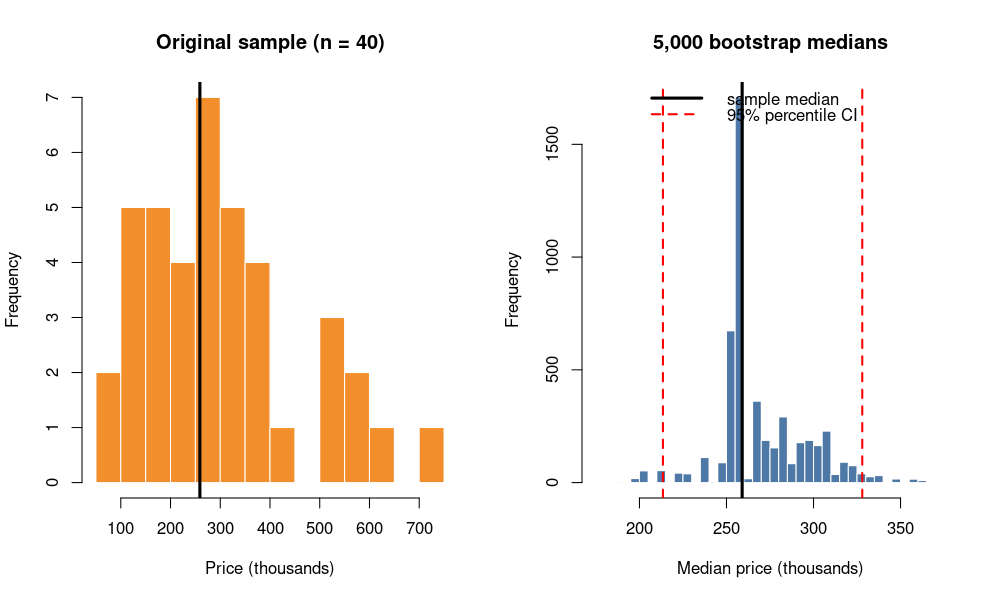

In [3]:
par(mfrow = c(1, 2))
hist(prices, breaks = 15, col = "#F28E2B", border = "white", main = "Original sample (n = 40)", xlab = "Price (thousands)")
abline(v = median(prices), lwd = 3, col = "black")

hist(boot_medians, breaks = 40, col = "#4E79A7", border = "white",
     main = "5,000 bootstrap medians", xlab = "Median price (thousands)")
abline(v = quantile(boot_medians, c(0.025, 0.975)), lwd = 2, lty = 2, col = "red")
abline(v = median(prices), lwd = 3)
legend("topright", c("sample median", "95% percentile CI"), lwd = c(3, 2), lty = c(1, 2), col = c("black", "red"), bty = "n")

*Insight: For the mean, the bootstrap interval nearly matches the classical t interval. That's a useful sanity check. The bootstrap's real value is for statistics like the median, where no simple formula exists.*

## 2. The `boot` Package and Better Intervals

The percentile interval is simple but can be biased for skewed statistics. The **BCa** (bias-corrected and accelerated) interval adjusts for bias and skewness; it is the recommended default. The `boot` package (shipped with R) computes it.

Below: a bootstrap CI for a **correlation**, using R's built-in `faithful` data (Old Faithful geyser eruptions).

In [4]:
library(boot)
cor_stat <- function(data, idx) cor(data$eruptions[idx], data$waiting[idx])

set.seed(212)
bt <- boot(faithful, statistic = cor_stat, R = 5000)
bt
boot.ci(bt, type = c("perc", "bca"))
cat("Classical (Fisher z) CI from cor.test:", round(cor.test(faithful$eruptions, faithful$waiting)$conf.int, 4), "\n")


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = faithful, statistic = cor_stat, R = 5000)


Bootstrap Statistics :
     original       bias    std. error
t1* 0.9008112 0.0001704073 0.008950919

BOOTSTRAP CONFIDENCE INTERVAL CALCULATIONS
Based on 5000 bootstrap replicates

CALL : 
boot.ci(boot.out = bt, type = c("perc", "bca"))

Intervals : 
Level     Percentile            BCa          
95%   ( 0.8826,  0.9177 )   ( 0.8809,  0.9161 )  
Calculations and Intervals on Original Scale

Classical (Fisher z) CI from cor.test: 0.8757 0.9211 


## 3. Permutation Tests

A permutation test answers: *if the group labels didn't matter ($H_0$), how unusual is the difference we observed?*

1. Compute the observed statistic, e.g. $\bar{x}_B - \bar{x}_A$.
2. **Shuffle** the group labels randomly (keeping group sizes) and recompute the statistic.
3. Repeat thousands of times to build the **null distribution**.
4. p-value = share of shuffled statistics at least as extreme as the observed one.

It makes no normality assumption — only that, under $H_0$, observations are **exchangeable** between groups (true in a randomised experiment).

Observed difference (B - A): 18.9 seconds


Permutation p-value (two-sided): 0.0344


Welch t-test p-value           : 0.0368


Mann-Whitney p-value           : 0.0232


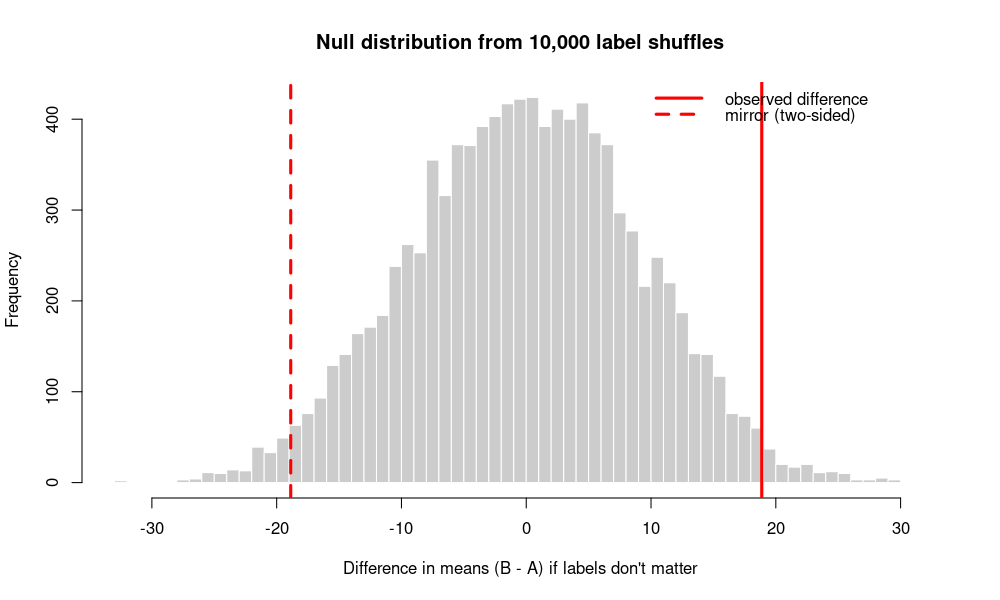

In [5]:
set.seed(233)
# Time on page (seconds) for two page designs: skewed data, small samples
design_A <- round(rexp(18, rate = 1/40))
design_B <- round(rexp(22, rate = 1/62))
values <- c(design_A, design_B)
labels <- rep(c("A", "B"), c(length(design_A), length(design_B)))

diff_means <- function(v, g) mean(v[g == "B"]) - mean(v[g == "A"])
observed <- diff_means(values, labels)

perm_null <- replicate(10000, diff_means(values, sample(labels)))
p_perm <- mean(abs(perm_null) >= abs(observed))

cat(sprintf("Observed difference (B - A): %.1f seconds\n", observed))
cat(sprintf("Permutation p-value (two-sided): %.4f\n", p_perm))
cat(sprintf("Welch t-test p-value           : %.4f\n", t.test(design_B, design_A)$p.value))
cat(sprintf("Mann-Whitney p-value           : %.4f\n", wilcox.test(design_B, design_A, exact = FALSE)$p.value))

hist(perm_null, breaks = 60, col = "grey80", border = "white",
     main = "Null distribution from 10,000 label shuffles", xlab = "Difference in means (B - A) if labels don't matter")
abline(v = c(-1, 1) * observed, col = "red", lwd = 3, lty = c(2, 1))
legend("topright", c("observed difference", "mirror (two-sided)"), col = "red", lwd = 3, lty = c(1, 2), bty = "n")

## 4. Any Statistic, Same Recipe

The power of permutation tests is flexibility: swap in **any** statistic, such as the difference in medians, a ratio of variances, or a correlation, and the procedure stays the same. Here is a test for a difference in **medians**, which no classical test addresses directly.

In [6]:
diff_medians <- function(v, g) median(v[g == "B"]) - median(v[g == "A"])
obs_med <- diff_medians(values, labels)
null_med <- replicate(10000, diff_medians(values, sample(labels)))
cat(sprintf("Observed difference in medians: %.1f s, permutation p = %.4f\n", obs_med, mean(abs(null_med) >= abs(obs_med))))

# A bootstrap CI for the same difference in medians (resample within each group)
boot_diff <- replicate(5000, median(sample(design_B, replace = TRUE)) - median(sample(design_A, replace = TRUE)))
cat("95% bootstrap CI for the difference in medians:", round(quantile(boot_diff, c(0.025, 0.975)), 1), "\n")

Observed difference in medians: 25.5 s, permutation p = 0.0268


95% bootstrap CI for the difference in medians: 6 43 


## 5. When Resampling Fails

Resampling is not magic. It can only reflect information that is in the sample:

- **Very small samples** (say $n < 10$): the sample is a poor stand-in for the population.
- **Extreme statistics** such as the maximum or minimum: a bootstrap sample can never exceed the observed maximum.
- **Dependent data** (time series, clustered data): resampling individual points destroys the dependence; use block or cluster bootstrap variants.
- **Non-random samples**: no amount of resampling fixes a biased sample.

Sample max: 99.77 | share of bootstrap maxima equal to the sample max: 0.654 


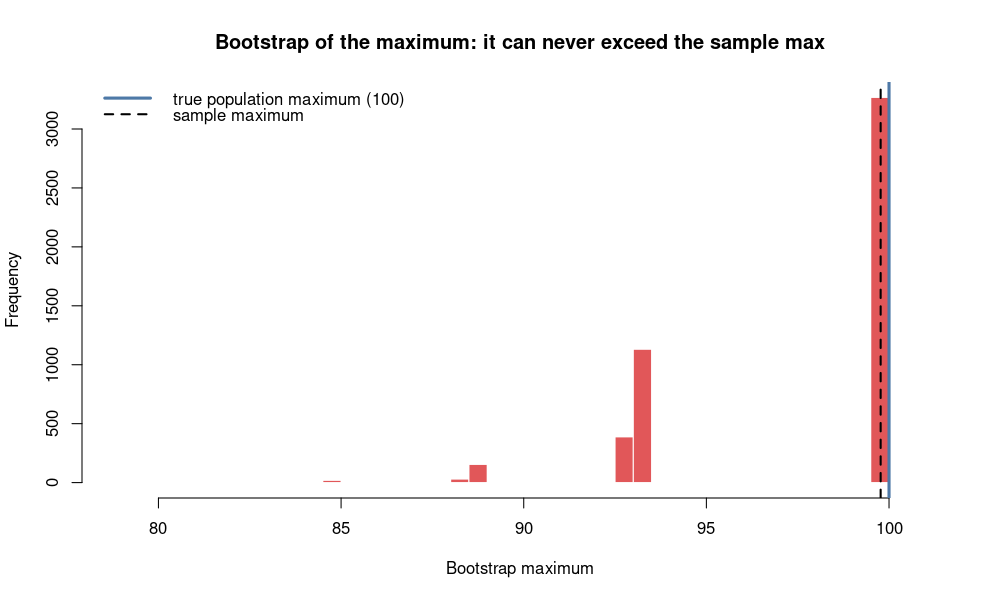

In [7]:
set.seed(215)
x <- runif(30, 0, 100)            # true maximum of the population is 100
boot_max <- replicate(5000, max(sample(x, replace = TRUE)))
cat("Sample max:", round(max(x), 2), "| share of bootstrap maxima equal to the sample max:",
    round(mean(boot_max == max(x)), 3), "\n")
hist(boot_max, breaks = 40, col = "#E15759", border = "white", xlim = c(min(boot_max), 101),
     main = "Bootstrap of the maximum: it can never exceed the sample max", xlab = "Bootstrap maximum")
abline(v = 100, lwd = 3, col = "#4E79A7"); abline(v = max(x), lwd = 2, lty = 2)
legend("topleft", c("true population maximum (100)", "sample maximum"), col = c("#4E79A7", "black"),
       lwd = c(3, 2), lty = c(1, 2), bty = "n")

*Insight: Use the bootstrap for **uncertainty** (SEs and CIs) of smooth statistics such as means, medians, correlations and regression coefficients. Use permutation tests for **p-values** in randomised comparisons. Both scale to complex statistics, which makes them a favourite tool in machine learning, for example for confidence intervals on a model's accuracy.*

## Real-World Use Case or Analogy

- **Bootstrap**: imagine estimating how much a soup's saltiness varies from spoon to spoon, but you have only one pot. You taste many spoonfuls from the same pot (with replacement) to see how much a single spoonful can mislead you.
- **Permutation test**: a magician claims a "lucky" deck. Shuffle the cards thousands of times and see how often an ordinary shuffle produces a hand as good as the magician's. If it happens often, the deck isn't special.

In industry, bootstrapping is used for confidence intervals on business metrics (median order value, revenue per user), and permutation tests are common in A/B testing platforms and genomics.